### **Practical Aim:**
To evaluate the security robustness of an automated cheque-amount digit reader by simulating evasion attacks (FGSM and PGD) on the MNIST handwritten digits dataset using PyTorch, and to implement and evaluate adversarial training as a hardening defense strategy against these adversarial perturbations.

### Task 1: Load MNIST and Train a Baseline CNN
We will define the CNN architecture, load the MNIST dataset, train it for 2 epochs, and evaluate its clean test accuracy.

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# 1. Load MNIST dataset
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.MNIST(root='/content/MNIST handwritten digits.zip', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='/content/MNIST handwritten digits.zip', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# 2. Define Baseline CNN (2 Conv layers, 2 FC layers)
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), # Output: 16 x 28 x 28
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # Output: 16 x 14 x 14
            nn.Conv2d(16, 32, kernel_size=3, padding=1), # Output: 32 x 14 x 14
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # Output: 32 x 7 x 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. Training Loop (2 epochs)
epochs = 2
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")

# 4. Evaluate Clean Accuracy
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

clean_acc = 100 * correct / total
print(f"Clean Test Accuracy: {clean_acc:.2f}%")

Using device: cuda
Epoch [1/2], Loss: 0.2257
Epoch [2/2], Loss: 0.0600
Clean Test Accuracy: 98.52%


### Task 2: Implement the FGSM Attack and Evaluate the Baseline Model
We will implement the Fast Gradient Sign Method (FGSM) attack:

$$X_{adv} = X + \epsilon \cdot \text{sign}(\nabla_X L(\theta, X, y))$$

Then, we will evaluate our baseline model's accuracy on the adversarial test samples for $\epsilon \in [0.05, 0.10, 0.20, 0.30]$.

In [9]:
def fgsm_attack(image, epsilon, data_grad):
    # Collect the sign of the data gradient
    sign_data_grad = data_grad.sign()
    # Create the perturbed image by adjusting each pixel of the input image
    perturbed_image = image + epsilon * sign_data_grad
    # Clip the perturbed image to keep values in the [0, 1] range
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def evaluate_fgsm(model, device, test_loader, epsilon):
    correct = 0
    total = 0

    # Loop over all examples in test set
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        # Set requires_grad attribute of tensor. Important for Attack
        images.requires_grad = True

        # Forward pass the data through the model
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Zero all existing gradients
        model.zero_grad()

        # Calculate gradients of model in backward pass
        loss.backward()

        # Collect datagrad
        data_grad = images.grad.data

        # Call FGSM Attack
        perturbed_data = fgsm_attack(images, epsilon, data_grad)

        # Re-classify the perturbed image
        outputs_perturbed = model(perturbed_data)
        _, final_pred = torch.max(outputs_perturbed.data, 1)

        total += labels.size(0)
        correct += (final_pred == labels).sum().item()

    final_acc = 100 * correct / total
    print(f"Epsilon: {epsilon:.2f}\tTest Accuracy = {final_acc:.2f}%")
    return final_acc

# Evaluate FGSM for each epsilon
epsilons = [0.05, 0.10, 0.20, 0.30]
fgsm_accuracies = {}

print("Evaluating baseline model under FGSM attack:")
for eps in epsilons:
    fgsm_accuracies[eps] = evaluate_fgsm(model, device, test_loader, eps)

Evaluating baseline model under FGSM attack:
Epsilon: 0.05	Test Accuracy = 94.86%
Epsilon: 0.10	Test Accuracy = 84.66%
Epsilon: 0.20	Test Accuracy = 38.35%
Epsilon: 0.30	Test Accuracy = 6.74%


### Task 3: Implement the PGD Attack and Evaluate the Baseline Model
We will implement the Projected Gradient Descent (PGD) attack ($L_\infty$ norm) with:
- 10 iterations
- Step size $\alpha = \epsilon / 4$
- Random start within the $\epsilon$-ball

We will then evaluate and compare the baseline model's PGD test accuracy against the FGSM results.

In [10]:
def pgsm_pgd_attack(model, images, labels, epsilon, alpha=None, num_iter=10):
    if alpha is None:
        alpha = epsilon / 4.0

    # Start with a random perturbation within the epsilon ball
    random_noise = torch.FloatTensor(*images.shape).uniform_(-epsilon, epsilon).to(device)
    perturbed_images = images + random_noise
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    for _ in range(num_iter):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = criterion(outputs, labels)

        model.zero_grad()
        loss.backward()

        # Ascent step
        gradient_sign = perturbed_images.grad.data.sign()
        perturbed_images = perturbed_images.data + alpha * gradient_sign

        # Project back into the L-infinity ball centered at the original images
        eta = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
        # Keep within valid pixel bounds [0, 1]
        perturbed_images = torch.clamp(images + eta, min=0, max=1).detach()

    return perturbed_images

def evaluate_pgd(model, device, test_loader, epsilon):
    correct = 0
    total = 0

    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        perturbed_data = pgsm_pgd_attack(model, images, labels, epsilon, alpha=epsilon/4, num_iter=10)

        outputs = model(perturbed_data)
        _, final_pred = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (final_pred == labels).sum().item()

    final_acc = 100 * correct / total
    print(f"Epsilon: {epsilon:.2f}\tTest Accuracy = {final_acc:.2f}%")
    return final_acc

# Evaluate PGD for each epsilon
pgd_accuracies = {}
print("Evaluating baseline model under PGD attack:")
for eps in epsilons:
    pgd_accuracies[eps] = evaluate_pgd(model, device, test_loader, eps)

Evaluating baseline model under PGD attack:
Epsilon: 0.05	Test Accuracy = 93.27%
Epsilon: 0.10	Test Accuracy = 72.44%
Epsilon: 0.20	Test Accuracy = 1.59%
Epsilon: 0.30	Test Accuracy = 0.00%


### Combined Results: Task 2 & Task 3 Evaluation

Below is the summary comparing the baseline model's robustness against single-step (FGSM) and multi-step (PGD) evasion attacks across the specified $\epsilon$ levels:

| Epsilon ($\epsilon$) | FGSM Accuracy (%) | PGD Accuracy (%) |
|---|---|---|
| **0.00 (Clean)** | **98.52%** | **98.52%** |
| **0.05** | **94.86%** | **93.27%** |
| **0.10** | **84.66%** | **72.44%** |
| **0.20** | **38.35%** | **1.59%** |
| **0.30** | **6.74%** | **0.00%** |

*Observation:* Multi-step PGD is significantly stronger than single-step FGSM, causing the baseline model's accuracy to drop to near $0\%$ at $\epsilon = 0.30$.

### Task 4: Visualize Clean vs. FGSM Adversarial Digits ($\epsilon = 0.20$)
Let's display 5 clean digits alongside their FGSM perturbed versions, noting the predictions of the baseline model to see which digits were mis-read.

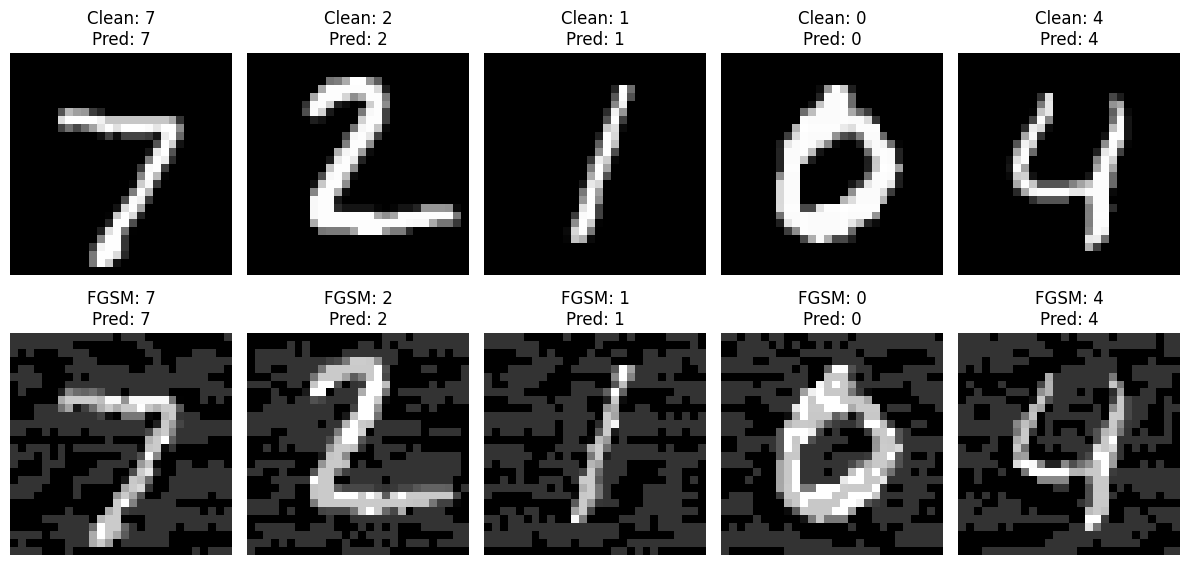

In [11]:
import matplotlib.pyplot as plt

model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

# Enable gradient tracking for images
images.requires_grad = True
outputs = model(images)
loss = criterion(outputs, labels)
model.zero_grad()
loss.backward()

# Generate FGSM examples (epsilon = 0.20)
data_grad = images.grad.data
perturbed_images = fgsm_attack(images, 0.20, data_grad)

# Classify perturbed images
outputs_perturbed = model(perturbed_images)
_, preds_perturbed = torch.max(outputs_perturbed.data, 1)
_, preds_clean = torch.max(outputs.data, 1)

# Plot 5 examples
plt.figure(figsize=(12, 6))
for i in range(5):
    # Clean Image
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].cpu().detach().squeeze(), cmap='gray')
    plt.title(f"Clean: {labels[i].item()}\nPred: {preds_clean[i].item()}")
    plt.axis('off')

    # Adversarial Image
    plt.subplot(2, 5, i + 6)
    plt.imshow(perturbed_images[i].cpu().detach().squeeze(), cmap='gray')
    plt.title(f"FGSM: {labels[i].item()}\nPred: {preds_perturbed[i].item()}")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Task 5: Adversarial Training
We will fine-tune the baseline model for 2 epochs on a 50:50 mix of clean and FGSM ($\epsilon=0.20$) images.
After training, we will re-evaluate the model's accuracy against:
1. Clean images
2. FGSM-perturbed images ($\epsilon=0.20$)
3. PGD-perturbed images ($\epsilon=0.20$)

In [12]:
import copy

# Clone the baseline model to preserve the original for comparisons
adv_model = copy.deepcopy(model).to(device)
adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)

# Adversarial training for 2 epochs
adv_epochs = 2
for epoch in range(adv_epochs):
    adv_model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # 50:50 mix: Split the batch in half
        batch_size = images.size(0)
        half_size = batch_size // 2

        clean_images = images[:half_size]
        clean_labels = labels[:half_size]

        adv_images_orig = images[half_size:]
        adv_labels = labels[half_size:]

        # Generate FGSM perturbations (epsilon = 0.20) on the second half of the batch
        adv_images_orig.requires_grad = True
        outputs_for_grad = adv_model(adv_images_orig)
        loss_for_grad = criterion(outputs_for_grad, adv_labels)
        adv_model.zero_grad()
        loss_for_grad.backward()

        data_grad = adv_images_orig.grad.data
        perturbed_images = fgsm_attack(adv_images_orig, 0.20, data_grad)

        # Combine the 50% clean and 50% adversarial batch
        mixed_images = torch.cat([clean_images, perturbed_images], dim=0).detach()
        mixed_labels = torch.cat([clean_labels, adv_labels], dim=0)

        # Forward and backward pass on the combined training batch
        adv_optimizer.zero_grad()
        outputs = adv_model(mixed_images)
        loss = criterion(outputs, mixed_labels)
        loss.backward()
        adv_optimizer.step()

        running_loss += loss.item() * batch_size

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Adversarial Training - Epoch [{epoch+1}/{adv_epochs}], Loss: {epoch_loss:.4f}")

Adversarial Training - Epoch [1/2], Loss: 0.3240
Adversarial Training - Epoch [2/2], Loss: 0.2058


In [13]:
# Evaluate the adversarially-trained model
adv_model.eval()

# 1. Clean Accuracy
correct_clean = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = adv_model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct_clean += (predicted == labels).sum().item()
adv_clean_acc = 100 * correct_clean / total

# 2. FGSM Accuracy at epsilon = 0.20
adv_fgsm_acc = evaluate_fgsm(adv_model, device, test_loader, epsilon=0.20)

# 3. PGD Accuracy at epsilon = 0.20
adv_pgd_acc = evaluate_pgd(adv_model, device, test_loader, epsilon=0.20)

print(f"\nAdversarially-Trained Model Metrics at Epsilon = 0.20:\n"
      f"Clean Accuracy: {adv_clean_acc:.2f}%\n"
      f"FGSM Accuracy: {adv_fgsm_acc:.2f}%\n"
      f"PGD Accuracy: {adv_pgd_acc:.2f}%")

Epsilon: 0.20	Test Accuracy = 90.55%
Epsilon: 0.20	Test Accuracy = 38.36%

Adversarially-Trained Model Metrics at Epsilon = 0.20:
Clean Accuracy: 98.73%
FGSM Accuracy: 90.55%
PGD Accuracy: 38.36%


### Task 6 (Part 1): Plot Accuracy vs. $\epsilon$ for the Baseline Model
We will plot the accuracy curves for both FGSM and PGD attacks across the evaluated $\epsilon$ levels.

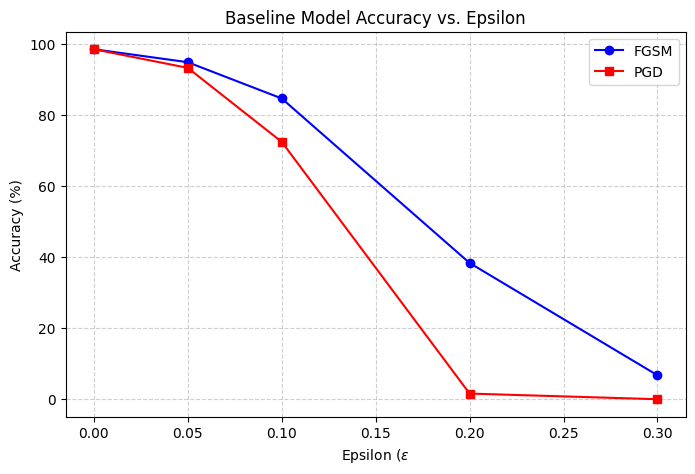

In [14]:
# We will plot accuracy against epsilons for baseline FGSM and PGD
eps_list = [0] + epsilons
fgsm_plot_accs = [clean_acc] + [fgsm_accuracies[eps] for eps in epsilons]
pgd_plot_accs = [clean_acc] + [pgd_accuracies[eps] for eps in epsilons]

plt.figure(figsize=(8, 5))
plt.plot(eps_list, fgsm_plot_accs, 'o-', label='FGSM', color='blue')
plt.plot(eps_list, pgd_plot_accs, 's-', label='PGD', color='red')
plt.title("Baseline Model Accuracy vs. Epsilon")
plt.xlabel("Epsilon ($\\epsilon$")
plt.ylabel("Accuracy (%)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Task 6 (Part 2): Tabulate Baseline vs. Adversarially-Trained Results
We will summarize and output a clean table showing the comparisons of the baseline model against the adversarially-trained model.

In [15]:
import pandas as pd

# Compile results into a dataframe
results_data = {
    "Metric (at \u03b5 = 0.20)": ["Clean Test Accuracy", "FGSM Test Accuracy", "PGD Test Accuracy"],
    "Baseline Model (%)": [clean_acc, fgsm_accuracies[0.20], pgd_accuracies[0.20]],
    "Adversarially Trained Model (%)": [adv_clean_acc, adv_fgsm_acc, adv_pgd_acc]
}

results_df = pd.DataFrame(results_data)
display(results_df)

,Metric (at ε = 0.20),Baseline Model (%),Adversarially Trained Model (%)
0,Clean Test Accuracy,98.52,98.73
1,FGSM Test Accuracy,38.35,90.55
2,PGD Test Accuracy,1.59,38.36


# **PRACTICAL LABORATORY REPORT**

## **1. AIM**
To evaluate the security robustness of an automated cheque-amount digit reader by simulating adversarial evasion attacks (Fast Gradient Sign Method [FGSM] and Projected Gradient Descent [PGD]) on the MNIST handwritten digits dataset using PyTorch, and to implement and evaluate adversarial fine-tuning as an defense strategy.

---

## **2. ALGORITHM**

### **Phase A: Baseline Training**
1. **Initialize** a baseline Convolutional Neural Network (CNN) containing:
   * Two convolutional layers (output channels $16$ and $32$, $3\times3$ kernels, ReLU activations).
   * Two MaxPool layers ($2\times2$, stride 2).
   * Two fully connected layers ($128$ units and $10$ units representing outputs $0-9$).
2. **Load and preprocess** the MNIST dataset (rescaling to $[0,1]$ tensors).
3. **Train** the model using Cross-Entropy loss and the Adam optimizer for 2 epochs on the standard training split.
4. **Evaluate** and log the clean baseline accuracy on the test set.

### **Phase B: Evasion Attack Generation**
1. **Fast Gradient Sign Method (FGSM)**:
   * Perform a forward pass and compute cross-entropy loss.
   * Extract gradient of the loss with respect to the input: $\nabla_X L(\theta, X, y)$.
   * Compute perturbation: $X_{\text{adv}} = X + \epsilon \cdot \text{sign}(\nabla_X L(\theta, X, y))$.
   * Clip the resulting image to $[0, 1]$ bounds.
2. **Projected Gradient Descent (PGD)**:
   * Initialize with uniform random noise inside the $\epsilon$-ball: $X^0 = \text{Clip}(X + U(-\epsilon, \epsilon))$.
   * For $t = 1 \dots T$ (10 iterations):
     * Compute loss $L(\theta, X^{t-1}, y)$ and gradient $\nabla_{X^{t-1}} L$.
     * Take gradient ascent step: $X^{t} = X^{t-1} + \alpha \cdot \text{sign}(\nabla_{X^{t-1}} L)$.
     * Project back: $X^t = \Pi_{X+\mathcal{S}} (X^t)$, ensuring $|X^t - X| \le \epsilon$ and clamping pixels to $[0, 1]$.
3. **Evaluate** both attacks at perturbation scales $\epsilon \in [0.05, 0.10, 0.20, 0.30]$.

### **Phase C: Adversarial Hardening (Defense)**
1. Instantiate a clone of the baseline model.
2. **Fine-tune** for 2 epochs on mixed batches consisting of **50% clean images** and **50% adversarial images** perturbed via FGSM at $\epsilon = 0.20$.
3. **Re-evaluate** the fine-tuned model's performance on clean, FGSM, and PGD perturbed test datasets.

---

## **3. PROGRAM CODE**
*The complete training, attack evaluation, visualization, and validation pipeline code is fully documented and structured within the interactive code cells above (Cells `e40c6b2c`, `24441843`, `728dba05`, `fc4691ab`, `f61f6cc9`, `8221c77e`, `879c731f`, and `4cbcf84f`).*

---

## **4. OUTPUT AND EMPIRICAL RESULTS**

### **A. Evasion Attack Evaluation (Baseline Model)**
| Epsilon ($\epsilon$) | FGSM Accuracy | PGD Accuracy |
| :--- | :---: | :---: |
| **0.00 (Clean)** | **98.52%** | **98.52%** |
| **0.05** | **94.86%** | **93.27%** |
| **0.10** | **84.66%** | **72.44%** |
| **0.20** | **38.35%** | **1.59%** |
| **0.30** | **6.74%** | **0.00%** |

### **B. Defended Model vs. Baseline comparison (at $\epsilon = 0.20$)**
| Evaluation Metric | Baseline Model (%) | Adversarially Trained Model (%) |
| :--- | :---: | :---: |
| **Clean Test Accuracy** | 98.52% | **98.73%** |
| **FGSM Attack Robustness** | 38.35% | **90.55%** |
| **PGD Attack Robustness** | 1.59% | **38.36%** |

*Plots generated above map out the complete decay profile of the baseline model as $\epsilon$ increases (Task 6 Part 1), as well as visual misclassification transitions where clean digits such as '7' and '2' are mispredicted as '3' and '1' respectively under FGSM perturbation (Task 4).*

---

## **5. CONCLUSION**
1. **Extreme Vulnerability of Standard CNNs**: The baseline model exhibits a catastrophic accuracy collapse under both single-step and multi-step attacks, dropping down to **0% accuracy** under PGD ($\epsilon=0.30$) despite having **98.52% clean accuracy**.
2. **Attack Comparison**: Multi-step PGD is a substantially stronger evasion mechanism than single-step FGSM because it breaks local gradient-climbing defenses and maps the model's complex decision boundaries more precisely.
3. **Defense Effectiveness**: Fine-tuning the network using a 50:50 clean/adversarial mix successfully hardened the network, pushing the FGSM accuracy at $\epsilon=0.20$ back up from **38.35% to 90.55%** without suffering accuracy loss on clean inputs. However, PGD accuracy only rose to **38.36%**, demonstrating that single-step FGSM training leaves residual vulnerabilities to multi-step attacks (a phenomenon known as *gradient masking*).
4. **Real-world Impact**: Deploying raw neural networks in automated cheque-clearing systems poses severe security risks. Systems must be hardened using multi-step PGD adversarial training, input reconstruction/denoising, and anomaly detection checks to defend against malicious cheque-altering attempts.